# Exercises with Convolutional Neural Networks

## Exercise 1: Loading a Pretrained Model

In [1]:
import torch.nn as nn
import torchvision.models as models
from torchvision.models import vgg16, VGG16_Weights

vgg16_model = models.vgg16(
    weights=VGG16_Weights.DEFAULT
)
print(vgg16_model)

### YOUR CODE HERE: get the number of trainable parameters in the model
num_params = sum(p.numel() for p in vgg16_model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params:,}")


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [2]:
import numpy as np
import torch
from PIL import Image #(package name is pillow - i.e. pip install pillow )

# Get example images from the internet, e.g. https://github.com/EliSchwartz/imagenet-sample-images
filename = '/Users/fangsiyu/Desktop/SDU-2026-fall-code/DL/n02483708_siamang.JPEG'

img = Image.open(filename)
img = np.array(img)
img = torch.from_numpy(img).permute(2, 0, 1)

# The following code is adapted from the PyTorch documentation
# See: https://docs.pytorch.org/vision/main/models.html#classification

# Step 1: Initialize model with the best available weights
weights = VGG16_Weights.DEFAULT
model = vgg16(weights=weights)
model.eval()

# Step 2: Initialize the inference transforms
preprocess = weights.transforms()   # [C, H, W] cropped and normalized

# Step 3: Apply inference preprocessing transforms
batch = preprocess(img).unsqueeze(0)    # [1, C, H, W]

# Step 4: Use the model and print the predicted category
prediction = model(batch).squeeze(0).softmax(0)     #[1, num_classes] -> [num_classes]
class_id = prediction.argmax().item()

score = prediction[class_id].item()
category_name = weights.meta["categories"][class_id]

# Print top 5 predictions
top5_prob, top5_catid = torch.topk(prediction, 5)
for i in range(top5_prob.size(0)):
    print(f"{weights.meta['categories'][top5_catid[i]]}: {100 * top5_prob[i].item():.1f}%")

siamang: 97.6%
gibbon: 1.6%
spider monkey: 0.7%
chimpanzee: 0.0%
howler monkey: 0.0%


Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


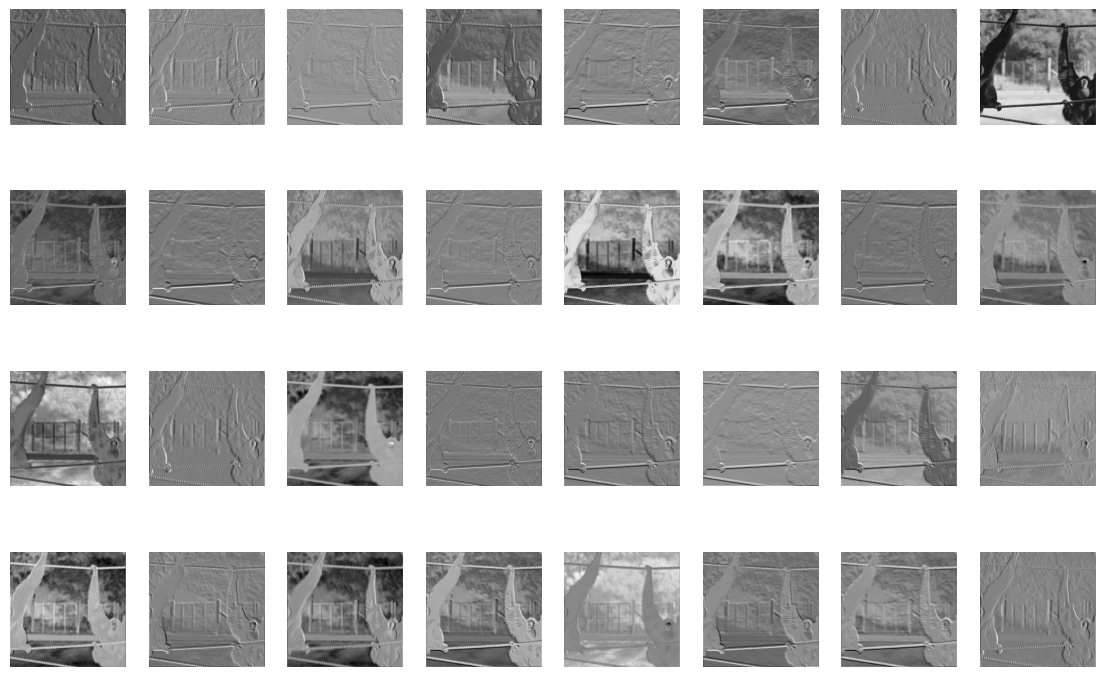

In [3]:
# Visualise what happens in the first conv layer channels
import matplotlib.pyplot as plt

first_conv_layer = model.features[0]
print(first_conv_layer)

with torch.no_grad():
    conv_output = first_conv_layer(batch)

fig, axes = plt.subplots(4, 8, figsize=(14, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(conv_output[0, i, :, :], cmap='gray')
    ax.axis("off")
plt.show()

## Exercise 2: Fine-tuning a large model
This task takes the previous exercise one step further, that we adjust the pretrained model to our needs. You will not need a lot of extra training to get a feasible model in this exercise, however if you want to get a really good model you will need to train for longer time and/or use more advanced techniques.

The model we use is the RESNET18 model (more lightweight than the VGG16 model). The model is pretrained on the ImageNet dataset, which contains 1.2 million images and 1000 classes. In this exercise we will fine-tune the model to classify the 10 classes in the CIFAR10 dataset (which should argueably build naturally on the ImageNet dataset).

In [1]:
from torchvision.models import resnet18, ResNet18_Weights

# Initialize model with the best available weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to("mps")
model.epoch_counter = 0 # custom attribute to count epochs
model.eval()

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [2]:
# get the cifar10 dataset (~163 MB download)
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import torch

training_data = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

train_loader = DataLoader(training_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print(f"Training data size: {len(training_data)}")
print(f"Test data size: {len(test_data)}")

Training data size: 50000
Test data size: 10000


In [3]:
# Function to evaluate the model
def evaluate(model, test_loader, prefix="Base performance"):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to("mps"), labels.to("mps")
            outputs = model(inputs)
            predicted = outputs.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    if prefix:
        print(f"{prefix} - Test Accuracy: {accuracy:.2f}%")
    else:
        print(f"Test Accuracy: {accuracy:.2f}%")
    pass

evaluate(model, test_loader)

Base performance - Test Accuracy: 0.06%


In [4]:
import torch.nn as nn

# Freeze all parameters
for param in model.parameters():
    param.requires_grad = False 

# modify the output layer to match the number of classes in CIFAR-10
num_classes = 10 # e.g. for CIFAR-10


# ============================================================
### ADJUST FOR PART B: replace the last layer of the model
# model.fc = nn.Linear(model.fc.in_features, num_classes).to('mps') # 512 - 10

### ADJUST FOR PART D: add a new layer on top of the model
# old_fc = model.fc
# model.fc = nn.Sequential(
#     old_fc,  # original weights, 512 - 1000
#     nn.LeakyReLU(),
#     nn.Linear(old_fc.out_features, num_classes), # 1000 - 10
# ).to('mps')

### FURTHER ADJUST FOR PART D: add a new block
model.fc = nn.Sequential(
    nn.Linear(512, 256),  # original weights, 512 - 256
    nn.LeakyReLU(),
    nn.Linear(256, num_classes), # 256 - 10
).to('mps')

# ============================================================
# # if VGG16
# # Part B
# model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

# # Part D
# old_fc = model.classifier[6]
# model.classifier[6] = nn.Sequential(
#     old_fc,
#     nn.Linear(old_fc.out_features, num_classes),
# )
# ============================================================



print(model.fc)

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=256, out_features=10, bias=True)
)


In [5]:
# Check the performance of the modified model on CIFAR-10
evaluate(model, test_loader, "Epoch 0 (no training)")

Epoch 0 (no training) - Test Accuracy: 9.95%


In [6]:
# Fine tune on the CIFAR-10 dataset
from tqdm import tqdm
import torch.optim as optim

EPOCHS = 10

# Unfreeze the last layer
# for param in model.fc.parameters(): # only unfrozen the last block!!
#     param.requires_grad = True

for param in model.fc[-1].parameters(): # only unfrozen the last layer!!
    param.requires_grad = True

model.train()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)
criterion = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    model.epoch_counter += 1

    running_loss = 0.0
    for i, (inputs, labels) in tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {model.epoch_counter}", leave=False):
        inputs, labels = inputs.to("mps"), labels.to("mps")
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch {model.epoch_counter}, Loss: {running_loss / len(train_loader)}")

evaluate(model, test_loader, f"Epochs {model.epoch_counter}")

Epoch 1, Loss: 1.684755425471479


Epoch 2, Loss: 1.5553747644204923


Epoch 3, Loss: 1.5079122155218783


Epoch 4, Loss: 1.4740732893004747


Epoch 5, Loss: 1.448407522400322


Epoch 6, Loss: 1.4239937489294945


Epoch 7, Loss: 1.3975629483342475


Epoch 8, Loss: 1.3853654266928164


Epoch 9, Loss: 1.365298074224721


Epoch 10, Loss: 1.3567164470929929
Epochs 10 - Test Accuracy: 48.58%


In [ ]:
# ResNet18 model - 512 - 10, unfreeze model.fc
# Epochs 10 - Test Accuracy: 44.84%

# ResNet18 model - 512 - 1000 - 10, unfreeze model.fc
# Epochs 10 - Test Accuracy: 41.38%



# ResNet18 model - 512 - 1000 - 10, with ReLU, unfreeze model.fc
# Epochs 10 - Test Accuracy: 47.85%

# ResNet18 model - 512 - 1000 - 10, with ReLU, unfreeze model.fc[-1]
# Epochs 10 - Test Accuracy: 41.61%


# ! new block
# ResNet18 model - 512 - 256 - 10, ! new block !, with ReLU, unfreeze model.fc
# Epochs 10 - Test Accuracy: 48.47%

# ResNet18 model - 512 - 256 - 10, ! new block !, with ReLU, unfreeze model.fc[-1]
# Epochs 10 - Test Accuracy: 48.58%

這個差距剛好就是 (d) 要你討論的東西。重點是：D 比較差不是因為模型能力比較弱，而是比較難訓練。

為什麼不是能力的問題

D 的結構是 512 → 1000 → 10，兩層 Linear 中間沒有 ReLU 之類的非線性。兩個線性層疊起來，數學上還是一個線性轉換，等於某一個 512 → 10 的矩陣。也就是說，D 能表示的函數，B 全部都能表示，反過來也一樣。所以理論上 D 最好也能做到跟 B 一樣的準確率，多加一層並沒有讓模型變強。

那為什麼差這麼多

兩種做法，新層看到的東西不同

ResNet 前面那一大串卷積層，最後會把每張圖整理成 512 個數字。你可以把它想成一份「這張圖的特徵描述」：哪裡有邊緣、有什麼紋理、大概是什麼形狀。這份描述是通用的，不是專門為哪個題目寫的。

B 的做法：新層直接讀這份 512 個數字的描述，學「什麼樣的特徵組合代表飛機、代表貓」。路徑很短，資訊也完整。

D 的做法：這份描述先經過原本 ImageNet 那層，被轉成 1000 個分數：「像金魚 3 分、像校車 12 分、像波斯貓 8 分…」。新層看到的是這 1000 個分數，要從這裡推回「這是 CIFAR-10 的哪一類」。

打個比方：B 是直接看照片的描述來作答；D 是看別人針對另一份考卷寫的答案，再從那份答案推你這份考卷的答案。資訊沒有消失，但變得很繞。

為什麼繞路會讓準確率變低
那 1000 個分數很難直接用。 CIFAR-10 的圖只有 32×32，非常模糊，ImageNet 那層看到這種圖，給出來的分數本來就很亂。而且有些分數特別大、有些特別小，新層要花更多時間才能學會怎麼看這些數字。同樣只訓練 10 個 epoch，B 已經學得差不多了，D 還在半路上。
原本那層一開始就被破壞。 你的訓練 cell 把 D 的整個 fc 都解凍了，包含原本那層。訓練剛開始時，新層還是隨機的，它往回傳給原本那層的修正方向基本上是亂的，等於在新層還沒學會之前，就先把原本訓練好的權重推亂了。

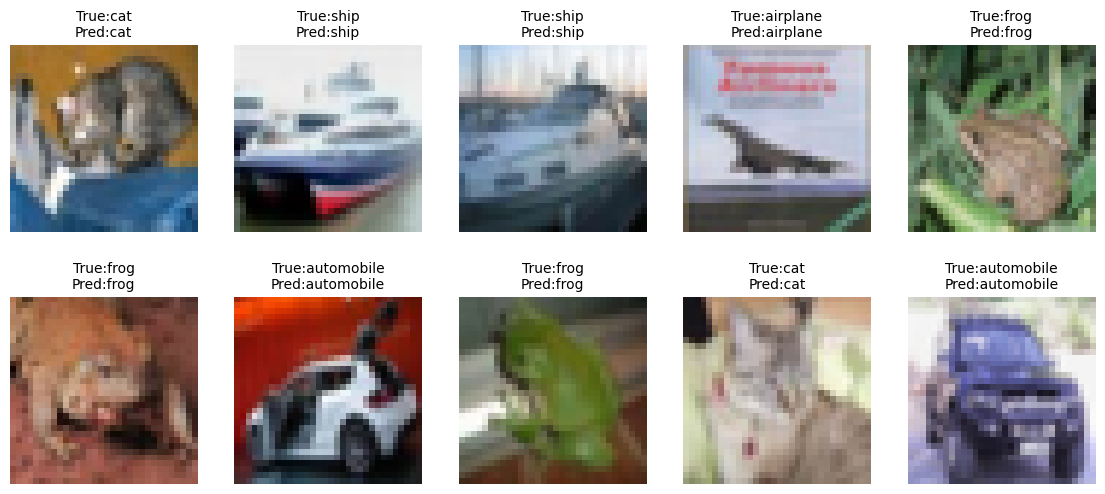

In [29]:
# Visualise some predictions on the test set
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i in range(10):
    ax = axes[i // 5, i % 5]
    inputs, labels = test_data[i]
    with torch.no_grad():
        outputs = model(inputs.unsqueeze(0).to("mps"))
        predicted = outputs.argmax(dim=1).item()
    
    class_names = test_data.classes
    ax.imshow(inputs.permute(1, 2, 0))
    ax.set_title(f"True:{class_names[labels]}\nPred:{class_names[predicted]}", fontsize=10)
    ax.axis("off")
plt.show()

---
## Ecercise 3: Convolution and Pooling on Images

$$\text{out} = \left\lfloor \frac{H + 2P - K}{S} \right\rfloor + 1$$
$H$：輸入的高（或寬）
$P$：padding，外圍補幾圈
$K$：kernel 的邊長
$S$：stride，每次移動幾格

image shape (512, 512)


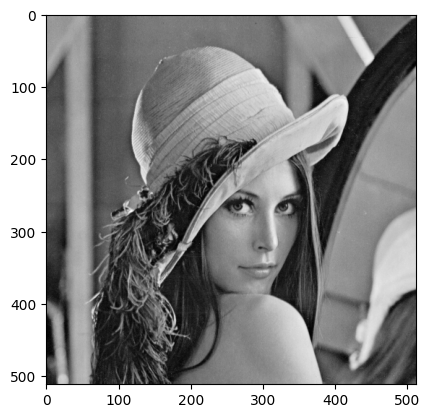

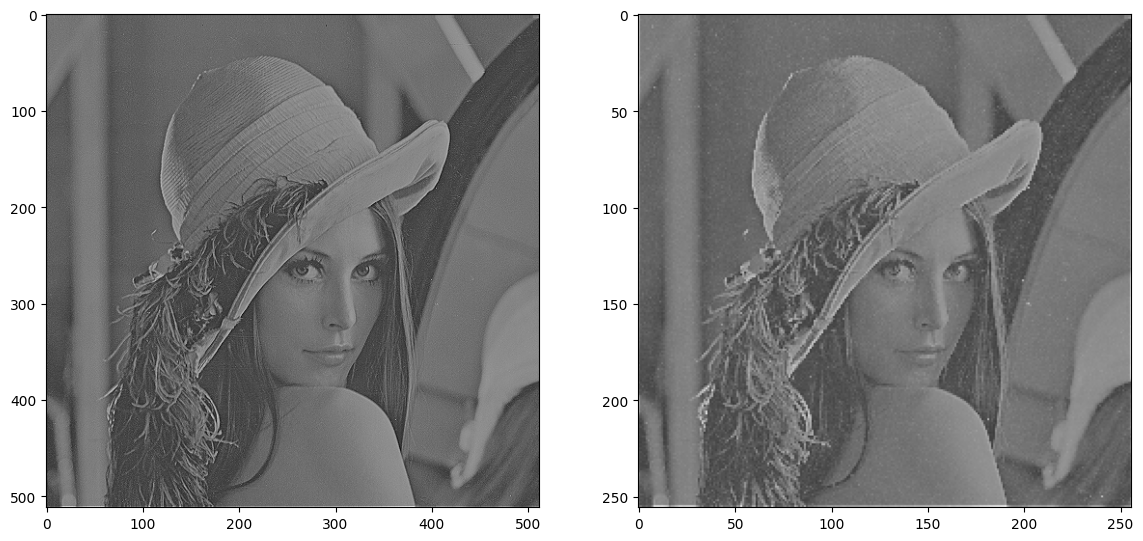

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image #(pacakge name is pillow - i.e. pip3 install pillow )
filename = 'lena512_gray.bmp'

img = Image.open('lena512_gray.bmp')
lena = np.array(img)
print('image shape', lena.shape)
plt.imshow(lena, cmap='gray')
plt.show()

def conv2d(img, w):
    """ Return the result of applying the convolution defined by w to img - 
    for simplicity assume that w is square"""
    w_dim = w.shape[0]
    pad = w_dim - 2
    padded_img = np.pad(img, [pad, pad], 'constant', constant_values=0)    
    out = np.zeros(img.shape)
    ### YOUR CODE HERE
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            window = padded_img[i : i+w_dim, j : j+w_dim]
            out[i,j] = np.sum(window * w)
    ### END CODE
    return out

def max_pool2d(img):
    """ Return the result of applying the 2 x 2 max pooling operator to img (halve the width and height of image)"""
    out = np.zeros((int(img.shape[0]/2), int(img.shape[1]/2)))
    ### YOUR CODE HERE
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            window = img[2*i : 2*i+2, 2*j : 2*j+2]
            out[i, j] = np.max(window)
    ### END CODE
    return out

# Test your implementations
# conv_filter = np.array([[-1., -1., -1.], 
#                         [-1., 8, -1.], 
#                         [-1., -1., -1.]])

conv_filter = np.array([[0., -1., 0.], 
                        [-1., 5., -1.], 
                        [0., -1., 0.]])

convoluted_lena = conv2d(lena, conv_filter)
# convoluted_lena = conv2d(conv2d(lena, conv_filter),conv_filter)
pooled_lena = max_pool2d(convoluted_lena)



fig, axes = plt.subplots(1, 2, figsize=(14, 9))
axes[0].imshow(convoluted_lena, cmap='gray', vmin=convoluted_lena.min(), vmax=convoluted_lena.max())
axes[1].imshow(pooled_lena, cmap='gray', vmin=convoluted_lena.min(), vmax=convoluted_lena.max())
plt.show()

image shape torch.Size([1, 1, 512, 512])
convoluted_lena shape torch.Size([1, 1, 512, 512])
conv diff norm 29735.815744653784
pool diff norm 19267.532405578044


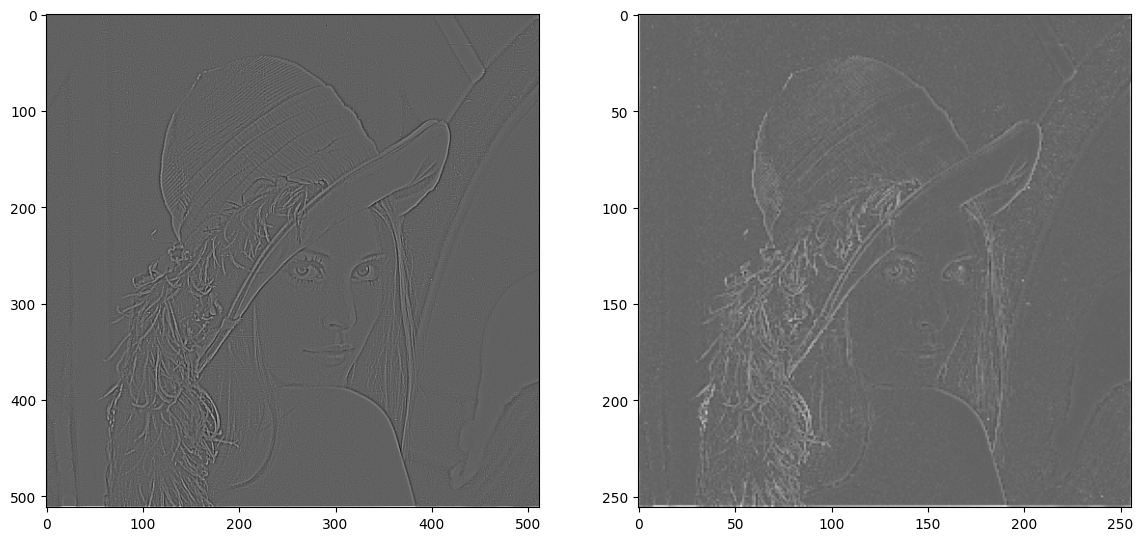

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch_lena = torch.from_numpy(lena).view(1, 1, lena.shape[0], lena.shape[1]).double()
print('image shape', torch_lena.shape)
tv = torch.tensor([[-1., -1., -1.], [-1., 8, -1.], [-1., -1., -1.]])
tv = tv.view(1, 1, 3, 3).double()
torch_convoluted_lena = F.conv2d(torch_lena, tv, torch.tensor([0.], dtype=torch.double), 1, 1, 1, 1)
print('convoluted_lena shape', torch_convoluted_lena.shape)
print('conv diff norm', np.linalg.norm(torch_convoluted_lena.numpy().squeeze() - convoluted_lena))
torch_pooled_lena = F.max_pool2d(torch_convoluted_lena, kernel_size=(2, 2))
print('pool diff norm', np.linalg.norm(torch_pooled_lena.numpy().squeeze() - pooled_lena))
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
axes[0].imshow(torch_convoluted_lena.numpy().squeeze(), cmap='gray', vmin=torch_convoluted_lena.min(), vmax=torch_convoluted_lena.max())
axes[1].imshow(torch_pooled_lena.numpy().squeeze(), cmap='gray', vmin=torch_convoluted_lena.min(), vmax=torch_convoluted_lena.max())
plt.show()

## Exercise 4: Information Theory on Images
In this exercise we will explore the concepts of entropy, mutual information, and unique information using simple image transformations. For a base example we will use image examples from CIFAR10, but you can use any images you like.

Hint: Completing the next frame is far from trivial, and I do not expect most of you to know outright how to implement these functions. This is a task where it is fine to find some code that works and then study it to understand how it works. You should know that there is not one single correct solution, what matters is implementing some sort of in-image and inter-image measures.

 - First steps could be to google around a bit terms like "image entropy", "image mutual information", and "skimage". 
 - If that doesn't help this is a good place to ask a friendly AI for a sketch of a solution or outright code. 
 - If all else fails, see the `entropy_hint.ipynb` for a solution that works. 

In [5]:
### STEP 1: implement the functions image_entropy and image_mutual_information
# These are library aided solutions that will work for the image entropy and mutual information bit.
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from sklearn.metrics import mutual_info_score
import torch

def image_entropy(image: np.ndarray) -> float:
    """ Compute the entropy of an image """
    return entropy((image*255).astype(np.uint8), disk(5)).mean()

def image_mutual_information(a: np.ndarray, b: np.ndarray) -> float:
    """ Compute the mutual information between two images a and b"""
    a = (a*255).astype(np.uint8).ravel()
    b = (b*255).astype(np.uint8).ravel()
    return mutual_info_score(a, b)

In [31]:
### STEP 2: Load data and apply transformations
import torchvision.transforms as transforms
from torchvision import datasets
import matplotlib.pyplot as plt

# Load a sample image from CIFAR10 (or use your own image)
dataset = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)


# dataset = transforms.ToTensor()(Image.open("/Users/fangsiyu/Desktop/SDU-2026-fall-code/DL/n02483708_siamang.JPEG").convert("RGB"))                         # PIL image -> tensor, values in [0, 1]


original_image, _ = dataset[0]

# These are some transformations that we apply in all cases
base_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),    # convert to grayscale for simplicity
    transforms.Resize((224, 224)),
])

# Here you add your own transformations to explore
# Hint: look at the torchvision.transforms module
transformations = [
    # --- Geometric: move / reshape pixels, content stays the same ---
    transforms.Compose([base_transform, transforms.RandomRotation(45)]),
    transforms.Compose([base_transform, transforms.RandomHorizontalFlip(p=1.0)]),
    transforms.Compose([base_transform, transforms.RandomVerticalFlip(p=1.0)]),
    transforms.Compose([base_transform, transforms.RandomAffine(degrees=0, translate=(0.2, 0.2))]),
    transforms.Compose([base_transform, transforms.RandomAffine(degrees=0, scale=(0.7, 1.3))]),
    transforms.Compose([base_transform, transforms.RandomAffine(degrees=0, shear=2)]),
    transforms.Compose([base_transform, transforms.RandomPerspective(distortion_scale=0.5, p=1.0)]),

    # --- Photometric: change brightness / contrast / sharpness, positions stay the same ---
    transforms.Compose([base_transform, transforms.ColorJitter(brightness=0.5)]),
    transforms.Compose([base_transform, transforms.ColorJitter(contrast=0.5)]),
    transforms.Compose([base_transform, transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))]),
    transforms.Compose([base_transform, transforms.RandomAdjustSharpness(sharpness_factor=3, p=1.0)]),
    transforms.Compose([base_transform, transforms.RandomInvert(p=1.0)]),

    # --- Occlusion: hide part of the image ---
    transforms.Compose([base_transform, transforms.RandomErasing(p=1.0)]),

    # --- Noise: add random pixel noise (useful for part d) ---
    transforms.Compose([base_transform, transforms.Lambda(lambda x: (x + 1 * torch.randn_like(x)).clamp(0, 1))]),

]

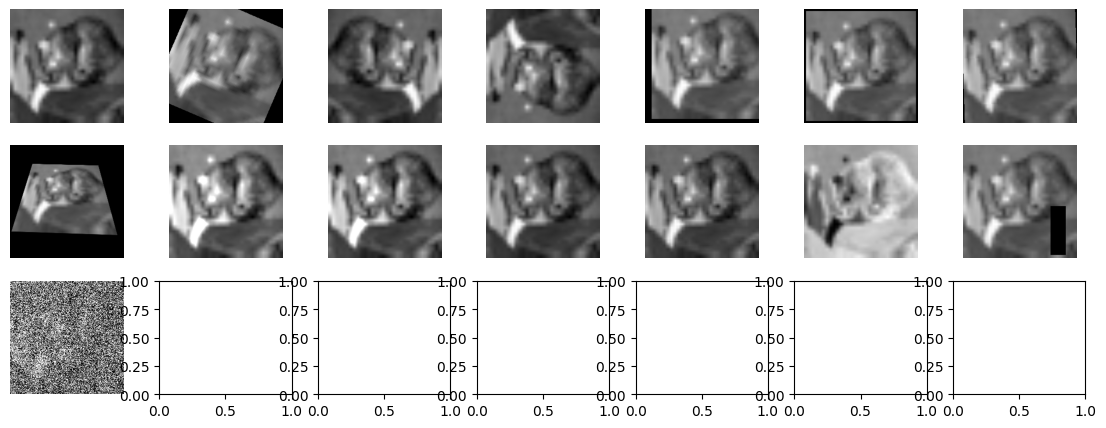

In [32]:
# Visualise the original and transformed images
fig, axes = plt.subplots(3, (len(transformations) + 1) // 2, figsize=(14, 5))
axes = axes.flatten()
    
axes[0].imshow(base_transform(original_image).squeeze(0).numpy(), cmap='gray')
axes[0].axis('off')

for i, transform in enumerate(transformations):
    transformed_image = transform(original_image).squeeze().numpy()
    axes[i + 1].imshow(transformed_image, cmap='gray')
    axes[i + 1].axis('off')
plt.show()

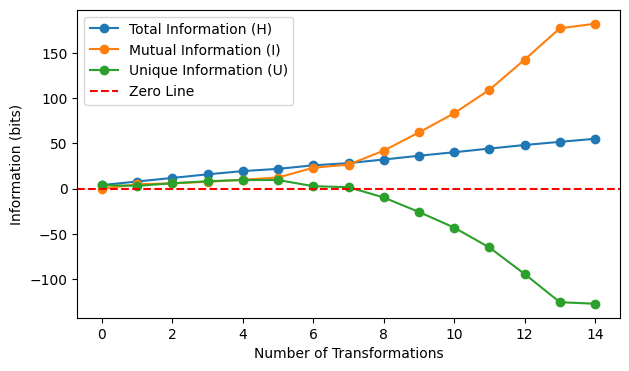

In [33]:
# Loop to show how the information changes as we augment the dataset with transformations

numpy_img = base_transform(original_image).squeeze(0).numpy()
base_entropy = image_entropy(numpy_img)

# Initialize lists to store the information values
total_informations = [base_entropy]
mutual_informations = [0]
unique_informations = [base_entropy]
images = [numpy_img]

for i, transform in enumerate(transformations):
    current_image = transform(original_image).squeeze(0).numpy()

    current_entropy = image_entropy(current_image)

    mi = 0  # mutual information with all previous images
    for previous_image in images:
        mi += image_mutual_information(previous_image, current_image)
    
    # Compute unique information using the formula: U(X;Y) = H(X) - I(X;Y)
    unique_info = current_entropy - mi
    
    # Update the lists
    total_informations.append(total_informations[-1]+current_entropy)
    mutual_informations.append(mutual_informations[-1]+mi)
    unique_informations.append(total_informations[-1] - mutual_informations[-1])
    images.append(current_image)

fig = plt.figure(figsize=(7, 4))
plt.plot(range(len(transformations) + 1), total_informations, label='Total Information (H)', marker='o')
plt.plot(range(len(transformations) + 1), mutual_informations, label='Mutual Information (I)', marker='o')
plt.plot(range(len(transformations) + 1), unique_informations, label='Unique Information (U)', marker='o')
plt.axhline(y=0, color='r', linestyle='--', label='Zero Line')
plt.legend()
plt.ylabel('Information (bits)')
plt.xlabel('Number of Transformations')
plt.show()

# blue: 單純是美一張新圖片的商
# orange: 每加一張新圖，就拿它跟前面每一張圖各比一次（包含原圖），把這些互資訊加總，再加到橘線原本的累積值上
# green: 藍色減上橘色，單純看差

# (d) 要討論到兩點，
# 第一，噪音的獨特但沒用處。橘色看出長很少，很獨特，但是這獨特是沒有意義的面向。因為是隨機的噪音點，並非真的有用的資訊可以幫助識別一物件
# 第二，即便噪音真的有獨特性，這獨特性要基於現實的獨特。例如早晚的光線差異。排社位置的不同等等。這些會是有用的獨特

---
## Exercise 5: Crosses and Pluses
In this dataset you have the opportunity to put all your deep learning skills into use. Build a model that can classify the images in the dataset. You can use any architecture you like, but you should be able to explain your choices. You can also use any techniques you have learned in the course, such as regularization, etc.

In [1]:
import h5py # pip install h5py
from sklearn.preprocessing import LabelEncoder

with h5py.File('crosses_and_pluses.h5', 'r') as f:
    train_data = f['data'][:]
    train_labels = f['labels'][:]

encoder = LabelEncoder()
train_labels = encoder.fit_transform(train_labels.ravel())

In [2]:
import torch
from sklearn.model_selection import train_test_split

X = torch.tensor(train_data, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(train_labels, dtype=torch.float32).reshape(-1, 1)

# Hold out the test set for final model evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.66, shuffle=True, random_state=42)

In [11]:
len(X_train), len(X_test)

(198, 102)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)


train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=16, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=16, shuffle=False)


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(1, 4, kernel_size=2),
            nn.SiLU(),
            nn.Conv3d(4, 1, kernel_size=2),
            nn.Flatten(),
        )

    def forward(self, x):
        return self.net(x)

model = SmallCNN().to('mps')

model.epoch_counter = 0
print(model)

SmallCNN(
  (net): Sequential(
    (0): Conv3d(1, 4, kernel_size=(2, 2, 2), stride=(1, 1, 1))
    (1): ReLU()
    (2): Conv3d(4, 1, kernel_size=(2, 2, 2), stride=(1, 1, 1))
    (3): Flatten(start_dim=1, end_dim=-1)
  )
)


In [5]:
def evaluate(model, test_loader, prefix="Base performance"):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to('mps'), labels.to('mps')
            outputs = model(inputs)
            predicted = (outputs > 0).float()   # logit > 0  <=>  probability > 0.5
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    if prefix:
        print(f"{prefix} - Test Accuracy: {accuracy:.2f}%")
    else:
        print(f"Test Accuracy: {accuracy:.2f}%")


evaluate(model, test_loader, "Epoch 0 (no training)")

Epoch 0 (no training) - Test Accuracy: 45.10%


In [6]:
# Training
EPOCHS = 5

model.train()
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.BCEWithLogitsLoss()

for epoch in range(EPOCHS):
    model.train()
    model.epoch_counter += 1

    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to('mps'), labels.to('mps')
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # if model.epoch_counter % 10 == 0:
    print(f"Epoch {model.epoch_counter}, Loss: {running_loss / len(train_loader):.4f}")

    evaluate(model, test_loader, f"Epochs {model.epoch_counter}")



Epoch 1, Loss: 0.5747
Epochs 1 - Test Accuracy: 90.20%
Epoch 2, Loss: 0.3377
Epochs 2 - Test Accuracy: 99.02%
Epoch 3, Loss: 0.1695
Epochs 3 - Test Accuracy: 100.00%
Epoch 4, Loss: 0.0839
Epochs 4 - Test Accuracy: 100.00%
Epoch 5, Loss: 0.0496
Epochs 5 - Test Accuracy: 100.00%


Epochs 5 - Test Accuracy: 100.00%
Test AUC: 1.000
Confusion matrix (rows = true, columns = predicted):
[[55  0]
 [ 0 47]]


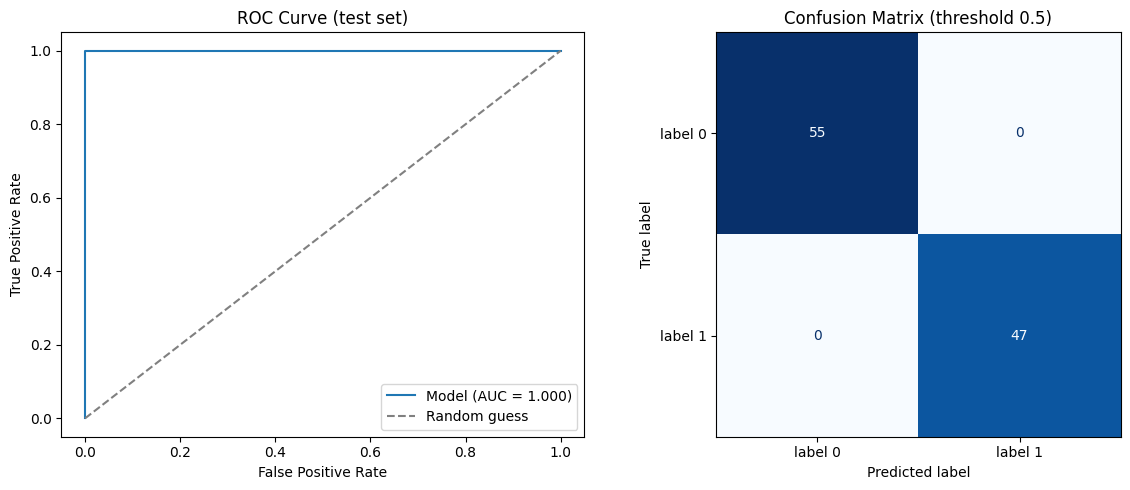

In [7]:
### Evaluate your out of sample performance on the test set
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

evaluate(model, test_loader, f"Epochs {model.epoch_counter}")

model.eval()
all_probs, all_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs.to('mps'))
        probs = torch.sigmoid(outputs).squeeze(1).cpu()   # logit -> probability of label 1
        all_probs.append(probs)
        all_labels.append(labels.squeeze(1))

y_prob = torch.cat(all_probs).numpy()
y_true = torch.cat(all_labels).numpy().astype(int)
y_pred = (y_prob > 0.5).astype(int)

# Metrics
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc = roc_auc_score(y_true, y_prob)
cm = confusion_matrix(y_true, y_pred)

print(f"Test AUC: {auc:.3f}")
print(f"Confusion matrix (rows = true, columns = predicted):\n{cm}")

# Plots
class_names = ["label 0", "label 1"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve (test set)")
axes[0].legend()

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion Matrix (threshold 0.5)")

plt.tight_layout()
plt.show()